In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('spotify_data clean.csv')


In [3]:
df.head()


,track_id,track_name,track_number,track_popularity,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type,track_duration_min
0,3EJS5LyekDim1Tf5rBFmZl,Trippy Mane (ft. Project Pat),4,0,True,Diplo,77,2812821,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.55
1,1oQW6G2ZiwMuHqlPpP27DB,OMG!,1,0,True,Yelawolf,64,2363438,"country hip hop, southern hip hop",4SUmmwnv0xTjRcLdjczGg2,OMG!,2025-10-31,1,single,3.07
2,7mdkjzoIYlf1rx9EtBpGmU,Hard 2 Find,1,4,True,Riff Raff,48,193302,NaN,3E3zEAL8gUYWaLYB9L7gbp,Hard 2 Find,2025-10-31,1,single,2.55
3,67rW0Zl7oB3qEpD5YWWE5w,Still Get Like That (ft. Project Pat & Starrah),8,30,True,Diplo,77,2813710,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.69
4,15xptTfRBrjsppW0INUZjf,ride me like a harley,2,0,True,Rumelis,48,8682,dark r&b,06FDIpSHYmZAZoyuYtc7kd,come closer / ride me like a harley,2025-10-30,2,single,2.39


In [4]:
df.shape

(8582, 15)

In [5]:
df.columns

Index(['track_id', 'track_name', 'track_number', 'track_popularity',
       'explicit', 'artist_name', 'artist_popularity', 'artist_followers',
       'artist_genres', 'album_id', 'album_name', 'album_release_date',
       'album_total_tracks', 'album_type', 'track_duration_min'],
      dtype='str')

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
track_number,8582.0,5.772547e+00,6.052792e+00,1.00,1.00,4.000,9.00,1.020000e+02
track_popularity,8582.0,5.235621e+01,2.381608e+01,0.00,39.00,58.000,71.00,9.900000e+01
artist_popularity,8582.0,6.973002e+01,1.964598e+01,0.00,60.00,74.000,84.00,1.000000e+02
artist_followers,8582.0,2.403472e+07,3.803180e+07,0.00,462320.00,6105547.000,27252551.00,1.455421e+08
album_total_tracks,8582.0,1.378944e+01,1.188713e+01,1.00,6.00,13.000,17.00,1.810000e+02
track_duration_min,8582.0,3.492805e+00,1.057970e+00,0.07,2.88,3.445,3.99,1.351000e+01


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8582 entries, 0 to 8581
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   track_id            8582 non-null   str    
 1   track_name          8582 non-null   str    
 2   track_number        8582 non-null   int64  
 3   track_popularity    8582 non-null   int64  
 4   explicit            8582 non-null   bool   
 5   artist_name         8579 non-null   str    
 6   artist_popularity   8582 non-null   int64  
 7   artist_followers    8582 non-null   int64  
 8   artist_genres       5221 non-null   str    
 9   album_id            8582 non-null   str    
 10  album_name          8582 non-null   str    
 11  album_release_date  8582 non-null   str    
 12  album_total_tracks  8582 non-null   int64  
 13  album_type          8582 non-null   str    
 14  track_duration_min  8582 non-null   float64
dtypes: bool(1), float64(1), int64(5), str(8)
memory usage: 1.9 MB


In [8]:
df.isnull().sum()


track_id                 0
track_name               0
track_number             0
track_popularity         0
explicit                 0
artist_name              3
artist_popularity        0
artist_followers         0
artist_genres         3361
album_id                 0
album_name               0
album_release_date       0
album_total_tracks       0
album_type               0
track_duration_min       0
dtype: int64

In [9]:
df.nunique()


track_id              8582
track_name            7462
track_number            54
track_popularity        98
explicit                 2
artist_name           2547
artist_popularity       96
artist_followers      3740
artist_genres          661
album_id              5205
album_name            4870
album_release_date    2384
album_total_tracks      82
album_type               3
track_duration_min     647
dtype: int64

In [10]:
Duplicate_count = df.duplicated().sum()
Total_rows = df.shape[0]
print(f"Total Rows: {Total_rows}")
print(f"Duplicated Rows: {Duplicate_count}")
print(f"Percentage: {(Duplicate_count/Total_rows)*100:.2f}%")

Total Rows: 8582
Duplicated Rows: 0
Percentage: 0.00%


In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df['artist_genres'] = df['artist_genres'].replace('N/A', np.nan)
df['artist_name'] = df['artist_name'].fillna('Unknown')
df['release_year'] = pd.to_datetime(df['album_release_date'], errors='coerce').dt.year
df[['album_release_date', 'release_year']].head()


,album_release_date,release_year
0,2025-10-31,2025
1,2025-10-31,2025
2,2025-10-31,2025
3,2025-10-31,2025
4,2025-10-30,2025


In [13]:
print("Mean :", round(float(df['track_popularity'].mean()), 4))
print("Median:", float(df['track_popularity'].median()))
print("Mode :", int(df['track_popularity'].mode()[0]))


Mean : 52.3562
Median: 58.0
Mode : 0


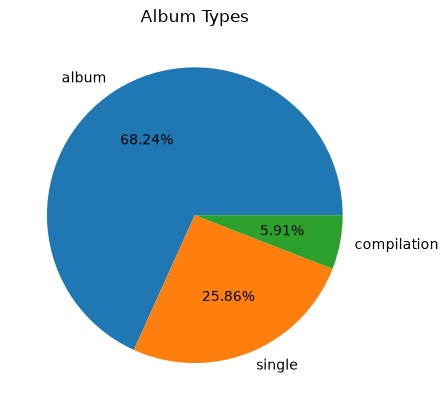

In [14]:
plt.pie(
 x=df['album_type'].value_counts().values,
 labels=df['album_type'].value_counts().index,
 autopct="%.2f%%"
)
plt.title("Album Types")
plt.show()


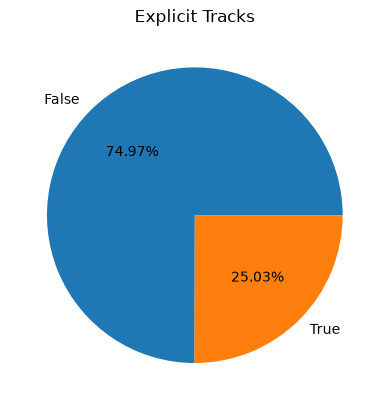

In [15]:
plt.pie(
 x=df['explicit'].value_counts().values,
 labels=df['explicit'].value_counts().index,
 autopct="%.2f%%"
)
plt.title("Explicit Tracks")
plt.show()


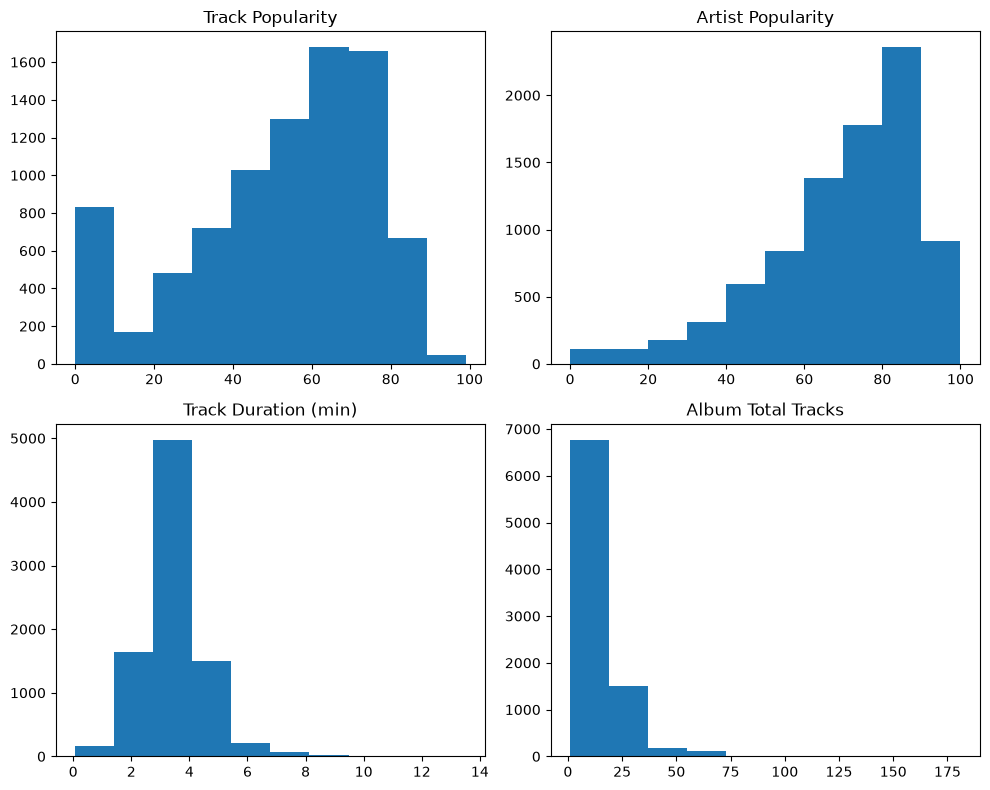

In [16]:
plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.hist(df['track_popularity'])
plt.title("Track Popularity")
plt.subplot(2, 2, 2)
plt.hist(df['artist_popularity'])
plt.title("Artist Popularity")
plt.subplot(2, 2, 3)
plt.hist(df['track_duration_min'])
plt.title("Track Duration (min)")
plt.subplot(2, 2, 4)
plt.hist(df['album_total_tracks'])
plt.title("Album Total Tracks")
plt.tight_layout()
plt.show()

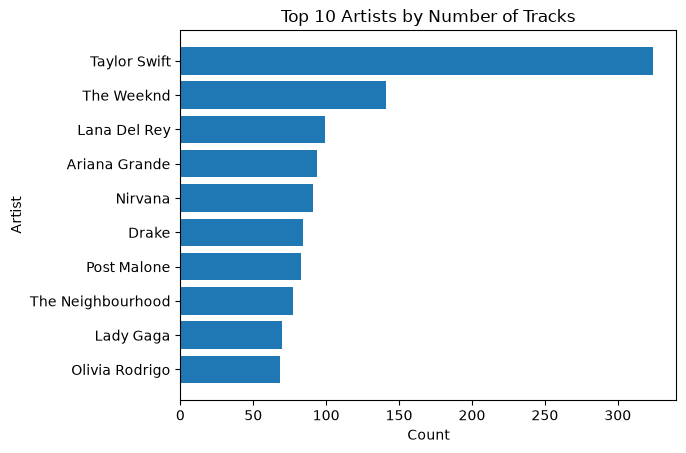

In [17]:
top_artists = df['artist_name'].value_counts().head(10)
plt.barh(top_artists.index[::-1], top_artists.values[::-1])
plt.title('Top 10 Artists by Number of Tracks')
plt.xlabel('Count')
plt.ylabel('Artist')
plt.show()

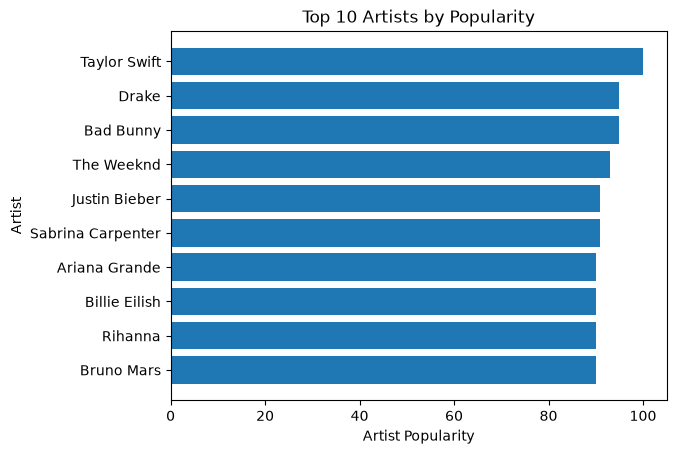

In [18]:
top_pop = df.drop_duplicates('artist_name').nlargest(10, 'artist_popularity')
plt.barh(top_pop['artist_name'][::-1], top_pop['artist_popularity'][::-1])
plt.title('Top 10 Artists by Popularity')
plt.xlabel('Artist Popularity')
plt.ylabel('Artist')
plt.show()

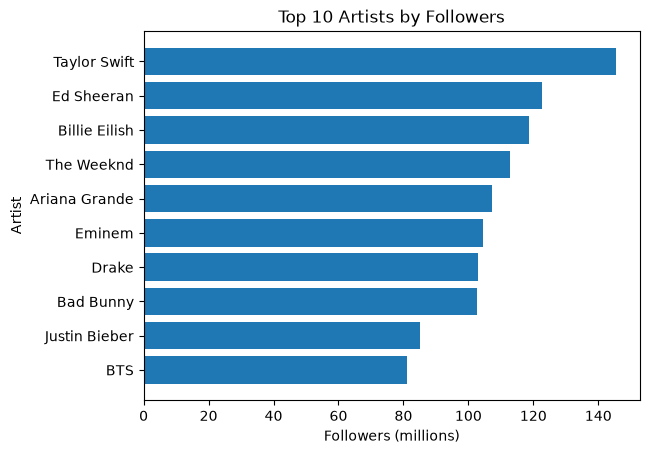

In [19]:
top_fol = df.drop_duplicates('artist_name').nlargest(10, 'artist_followers')
plt.barh(top_fol['artist_name'][::-1], top_fol['artist_followers'][::-1] / 1000000)
plt.title('Top 10 Artists by Followers')
plt.xlabel('Followers (millions)')
plt.ylabel('Artist')
plt.show()

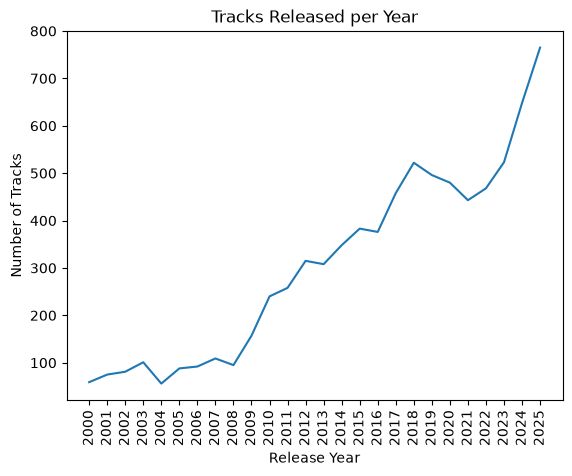

In [20]:
tracks_per_year = df[df['release_year'] >= 2000]['release_year'].value_counts().sort_index()
years = tracks_per_year.index.astype(int).astype(str)
plt.plot(years, tracks_per_year.values)
plt.title("Tracks Released per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=90)
plt.show()

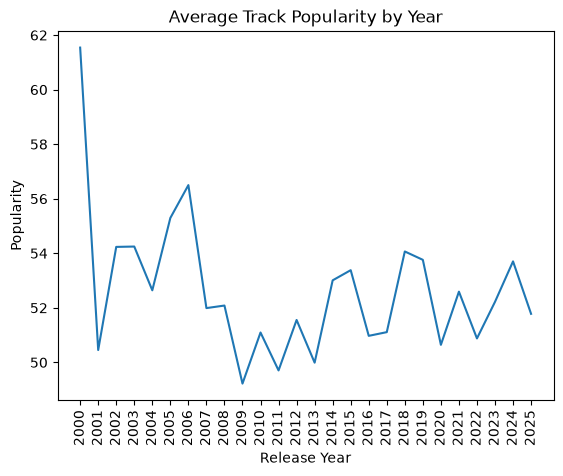

In [21]:
year_popularity = df[df['release_year'] >= 2000].groupby('release_year')['track_popularity'].mean()
years = year_popularity.index.astype(int).astype(str)
plt.plot(years, year_popularity.values)
plt.title("Average Track Popularity by Year")
plt.xlabel("Release Year")
plt.ylabel("Popularity")
plt.xticks(rotation=90)
plt.show()


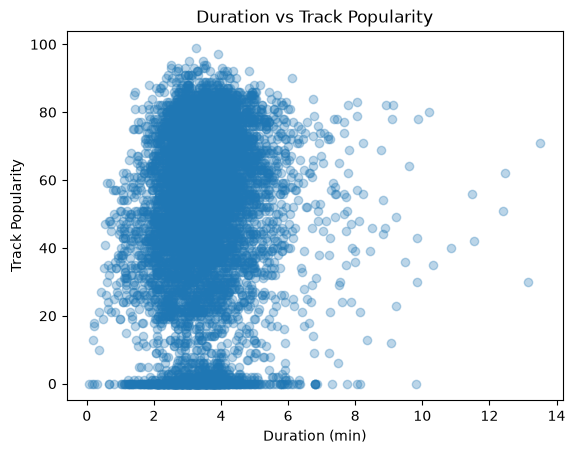

In [22]:
plt.scatter(df['track_duration_min'], df['track_popularity'], alpha=0.3)
plt.title("Duration vs Track Popularity")
plt.xlabel("Duration (min)")
plt.ylabel("Track Popularity")
plt.show()

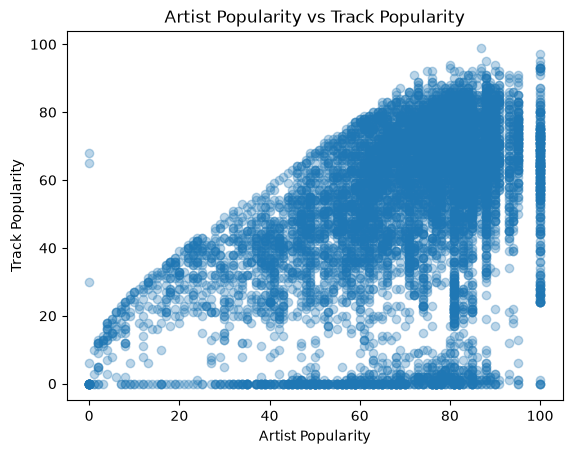

In [23]:
plt.scatter(df['artist_popularity'], df['track_popularity'], alpha=0.3)
plt.title("Artist Popularity vs Track Popularity")
plt.xlabel("Artist Popularity")
plt.ylabel("Track Popularity")
plt.show()

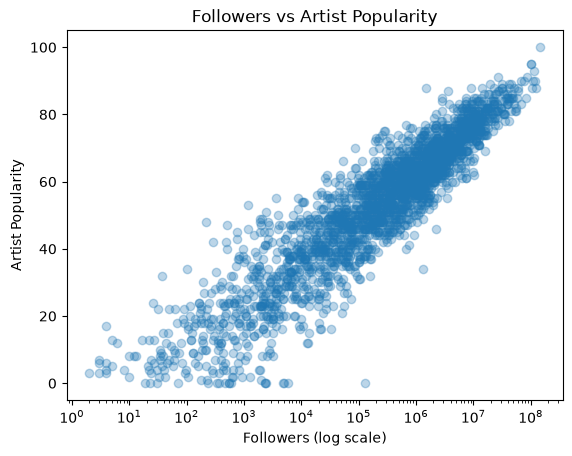

In [24]:
artists = df.drop_duplicates('artist_name')
plt.scatter(artists['artist_followers'], artists['artist_popularity'], alpha=0.3)
plt.xscale('log')
plt.title("Followers vs Artist Popularity")
plt.xlabel("Followers (log scale)")
plt.ylabel("Artist Popularity")
plt.show()

explicit
False    50.532639
True     57.818436
Name: track_popularity, dtype: float64


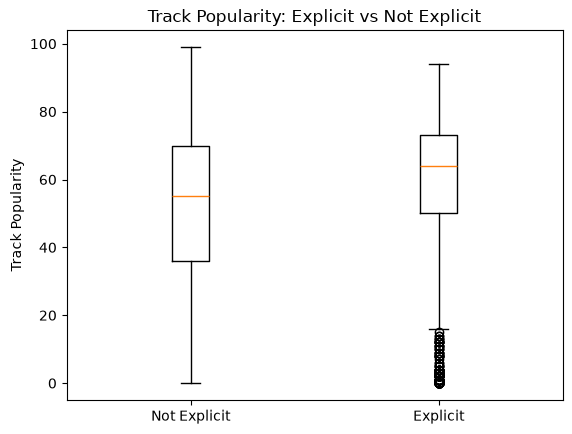

In [25]:
explicit_pop = df.groupby('explicit')['track_popularity'].mean()
print(explicit_pop)
plt.boxplot([df[df['explicit'] == False]['track_popularity'],
 df[df['explicit'] == True]['track_popularity']],
 tick_labels=['Not Explicit', 'Explicit'])
plt.title("Track Popularity: Explicit vs Not Explicit")
plt.ylabel("Track Popularity")
plt.show()

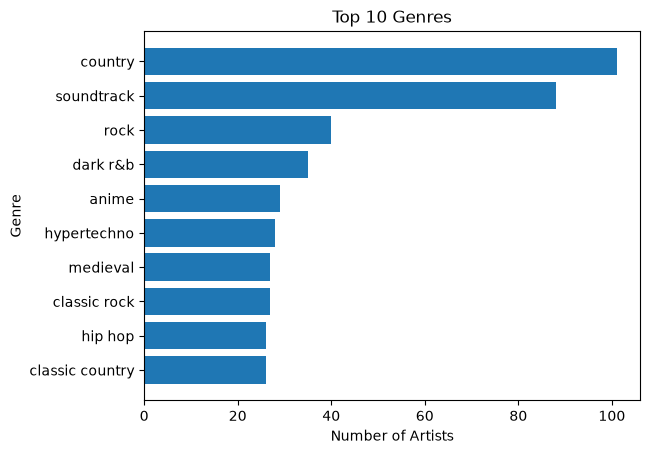

In [26]:
genres = df.drop_duplicates('artist_name')['artist_genres'].dropna().str.split(', ').explode()
top_genres = genres.value_counts().head(10)
plt.barh(top_genres.index[::-1], top_genres.values[::-1])
plt.title('Top 10 Genres')
plt.xlabel('Number of Artists')
plt.ylabel('Genre')
plt.show()

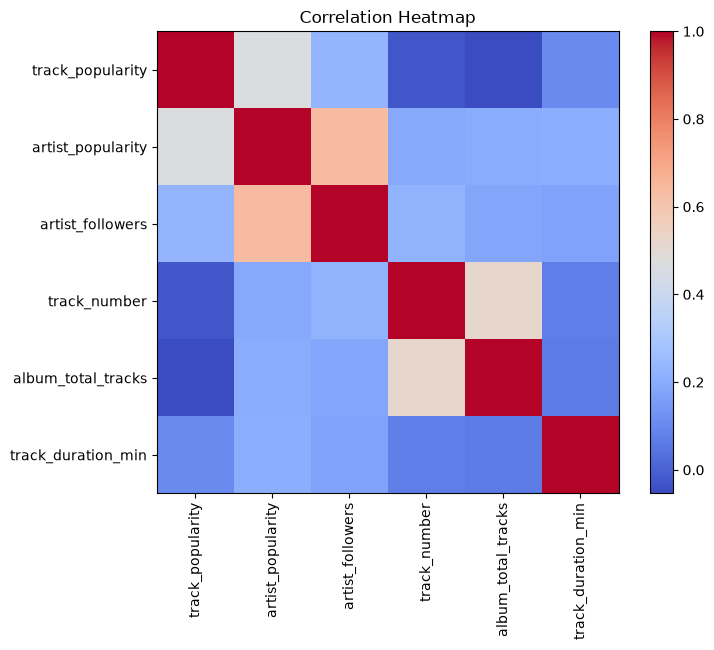

In [27]:
num_cols = ['track_popularity', 'artist_popularity', 'artist_followers',
'track_number', 'album_total_tracks', 'track_duration_min']
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.title("Correlation Heatmap")
plt.show()

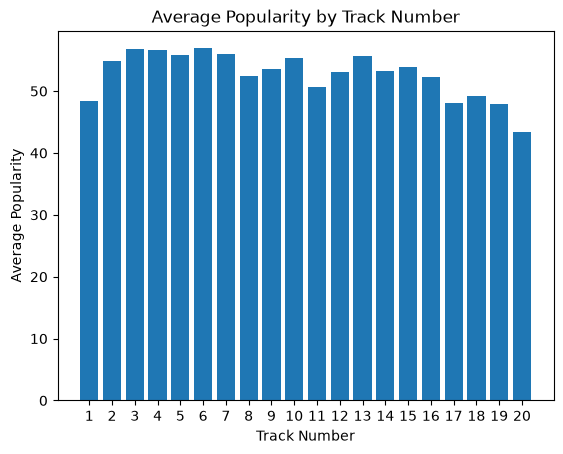

In [28]:
track_pos = df[df['track_number'] <= 20].groupby('track_number')['track_popularity'].mean()
plt.bar(track_pos.index.astype(str), track_pos.values)
plt.title("Average Popularity by Track Number")
plt.xlabel("Track Number")
plt.ylabel("Average Popularity")
plt.show()


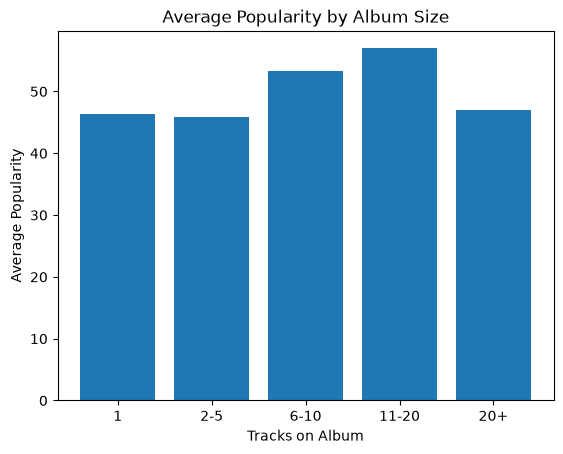

In [29]:
size_group = pd.cut(df['album_total_tracks'], [0, 1, 5, 10, 20, 200],
 labels=['1', '2-5', '6-10', '11-20', '20+'])
size_pop = df.groupby(size_group, observed=True)['track_popularity'].mean()
plt.bar(size_pop.index.astype(str), size_pop.values)
plt.title("Average Popularity by Album Size")
plt.xlabel("Tracks on Album")
plt.ylabel("Average Popularity")
plt.show()


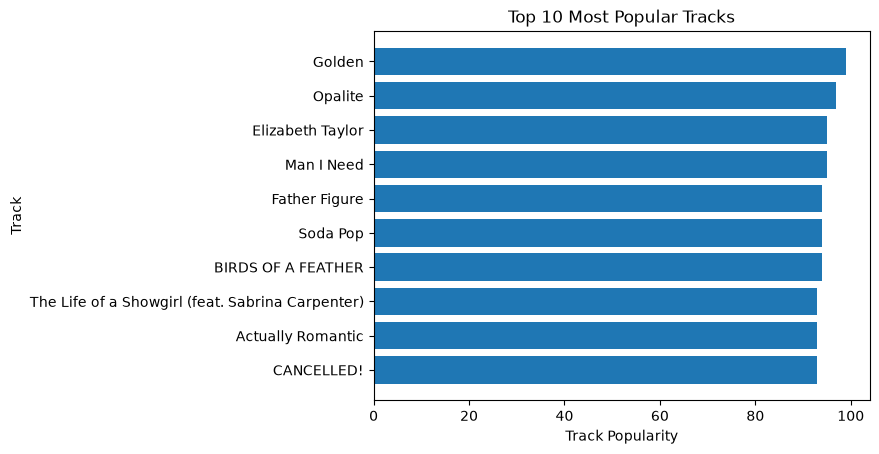

In [30]:
top_tracks = df.nlargest(10, 'track_popularity')
plt.barh(top_tracks['track_name'][::-1], top_tracks['track_popularity'][::-1])
plt.title('Top 10 Most Popular Tracks')
plt.xlabel('Track Popularity')
plt.ylabel('Track')
plt.show()

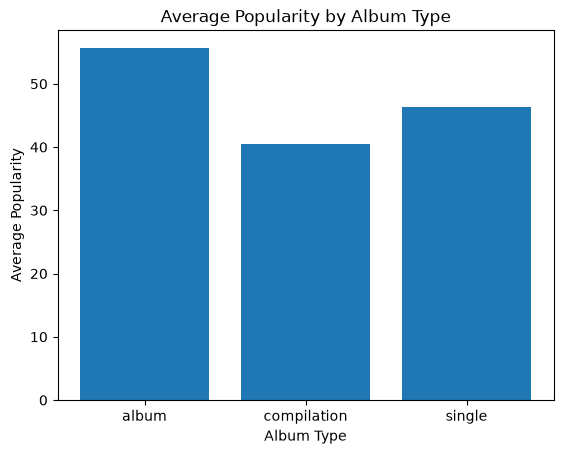

In [31]:
type_pop = df.groupby('album_type')['track_popularity'].mean()
plt.bar(type_pop.index, type_pop.values)
plt.title("Average Popularity by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Average Popularity")
plt.show()


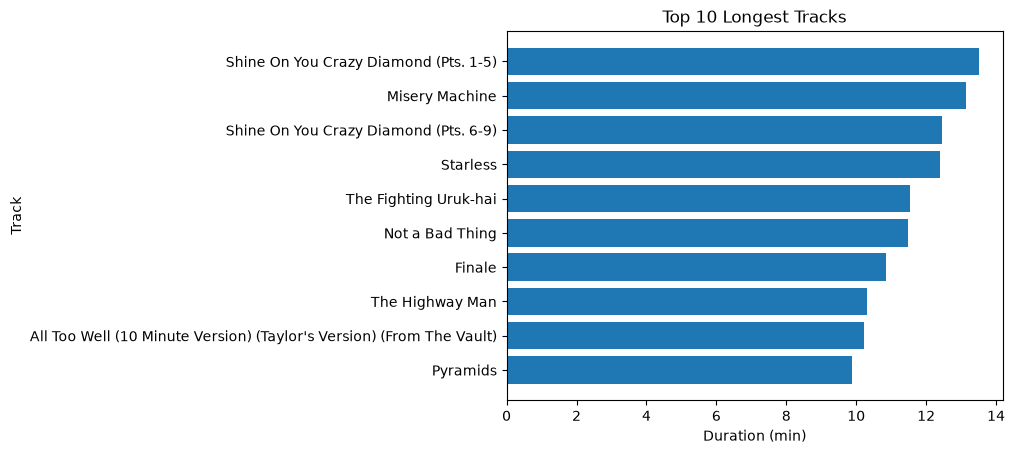

In [32]:
longest = df.nlargest(10, 'track_duration_min')
plt.barh(longest['track_name'][::-1], longest['track_duration_min'][::-1])
plt.title('Top 10 Longest Tracks')
plt.xlabel('Duration (min)')
plt.ylabel('Track')
plt.show()